# Women's Tennis Upsets 2000 - 2025: Exploratory Data Analysis

This notebook contains the Exploratory Data Analysis part of the project, investigating how often lower-ranked players defeated
higher-ranked players during the Women's Tennis Association (WTA) seasons from 2000 to 2025.

Our aims are as follows:
1. Download the raw data and combine the data sets into one file.
2. Inspect the data, checking column names, data types, number of rows etc.
3. Check for missing values, and decide how to deal with them.
4. Define an upset, and add a column "is_upset" holding a boolean variable of whether the match was an upset (True) or not an upset (False).
5. Calculate the ranking gap between players in each match.
6. Group the data into categories for each of the features surface, round, and ranking gap.
7. Create visualisations to compare how each of these features relate to the upset rates.

Along the way, we also make plots for a few other natural comparisons, for example gaining insight into the total number of matches in a single WTA season.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.ticker import PercentFormatter
from pathlib import Path

In order to run this project you must download the raw data files and put them into a folder data/raw/. These appear as separate CSV files for each year. In order to combine them into one CSV file, run the following code. This saved the CSV file into the folder data/processed. 

In [2]:
Path("../data/processed").mkdir(parents=True, exist_ok=True)
Path("../figures").mkdir(parents=True, exist_ok=True)

In [3]:
input_folder = Path("../data/raw")
output_folder = Path("../data/processed")
output_folder.mkdir(parents=True, exist_ok=True)

files = sorted(input_folder.glob("*.csv"))

combined = pd.concat(
    (pd.read_csv(file) for file in files),
    ignore_index=True
)

combined.to_csv(output_folder / "combined_data.csv", index=False)

In [4]:
df = pd.read_csv("../data/processed/combined_data.csv")
df.head()

/var/folders/by/8k32rhb11dvgnpbx90n3dxbm0000gn/T/ipykernel_53727/1643188592.py:1: DtypeWarning: Columns (8: winner_seed, 16: loser_seed) have mixed types. Specify dtype option on import or set low_memory=False.
  df = pd.read_csv("../data/processed/combined_data.csv")


,tourney_id,tourney_name,surface,draw_size,tourney_level,tourney_date,match_num,winner_id,winner_seed,winner_entry,...,l_1stIn,l_1stWon,l_2ndWon,l_SvGms,l_bpSaved,l_bpFaced,winner_rank,winner_rank_points,loser_rank,loser_rank_points
0,2000-D001,Fed Cup G1 PO: JPN vs CHN,Hard,4,D,20000430,1,201419,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,190.0,121.0,125.0,205.0
1,2000-D001,Fed Cup G1 PO: JPN vs CHN,Hard,4,D,20000430,2,200085,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,22.0,1230.0,96.0,319.0
2,2000-D002,Fed Cup WG SF: USA vs BEL,Carpet,4,D,20001122,1,200652,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,4.0,3255.0,48.0,661.0
3,2000-D002,Fed Cup WG SF: USA vs BEL,Carpet,4,D,20001122,2,200128,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,2.0,5022.0,18.0,1398.0
4,2000-D003,Fed Cup WG SF: CZE vs ESP,Carpet,4,D,20001121,1,200017,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,9.0,2132.0,54.0,610.0


## Reviewing the data

We inspect the data first to check for anomolies and missing data.

In [5]:
df.shape

(71419, 49)

This tells us that there are 71419 rows in the data, and 49 columns.

Each row corresponds to a WTA match between 2000 and 2025, and there are many columns which tell us about the details of each match. Let's check the column names.

In [6]:
df.columns.tolist()

['tourney_id',
 'tourney_name',
 'surface',
 'draw_size',
 'tourney_level',
 'tourney_date',
 'match_num',
 'winner_id',
 'winner_seed',
 'winner_entry',
 'winner_name',
 'winner_hand',
 'winner_ht',
 'winner_ioc',
 'winner_age',
 'loser_id',
 'loser_seed',
 'loser_entry',
 'loser_name',
 'loser_hand',
 'loser_ht',
 'loser_ioc',
 'loser_age',
 'score',
 'best_of',
 'round',
 'minutes',
 'w_ace',
 'w_df',
 'w_svpt',
 'w_1stIn',
 'w_1stWon',
 'w_2ndWon',
 'w_SvGms',
 'w_bpSaved',
 'w_bpFaced',
 'l_ace',
 'l_df',
 'l_svpt',
 'l_1stIn',
 'l_1stWon',
 'l_2ndWon',
 'l_SvGms',
 'l_bpSaved',
 'l_bpFaced',
 'winner_rank',
 'winner_rank_points',
 'loser_rank',
 'loser_rank_points']

It is quite useful to know which type of data is stored in each column.

In [7]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 71419 entries, 0 to 71418
Data columns (total 49 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   tourney_id          71419 non-null  str    
 1   tourney_name        71419 non-null  str    
 2   surface             71306 non-null  str    
 3   draw_size           71419 non-null  int64  
 4   tourney_level       71419 non-null  str    
 5   tourney_date        71419 non-null  int64  
 6   match_num           71419 non-null  int64  
 7   winner_id           71419 non-null  int64  
 8   winner_seed         29884 non-null  object 
 9   winner_entry        9374 non-null   str    
 10  winner_name         71419 non-null  str    
 11  winner_hand         71418 non-null  str    
 12  winner_ht           64996 non-null  float64
 13  winner_ioc          71419 non-null  str    
 14  winner_age          71404 non-null  float64
 15  loser_id            71419 non-null  int64  
 16  loser_seed     

We can examine some further details about the data in each of the columns storing numerical data.

In [8]:
df.describe().T

,count,mean,std,min,25%,50%,75%,max
draw_size,71419.0,5.654899e+01,41.615779,2.0,32.0,32.0,96.0,128.0
tourney_date,71419.0,2.012184e+07,75354.113647,20000103.0,20060109.0,20120430.0,20180917.0,20251101.0
match_num,71419.0,1.096623e+02,169.740874,1.0,12.0,32.0,241.0,2701.0
winner_id,71419.0,2.038110e+05,6223.483338,200001.0,201297.0,201495.0,202494.0,267382.0
winner_ht,64996.0,1.736384e+02,6.599989,152.0,170.0,174.0,178.0,190.0
winner_age,71404.0,2.452828e+01,4.132903,14.0,21.4,24.3,27.3,47.6
loser_id,71419.0,2.040989e+05,6410.067190,200001.0,201320.0,201512.0,202709.0,270251.0
loser_ht,61654.0,1.729233e+02,6.525111,152.0,169.0,173.0,178.0,190.0
loser_age,71393.0,2.448951e+01,4.311003,14.0,21.3,24.2,27.4,48.6
best_of,71419.0,3.002156e+00,0.065635,3.0,3.0,3.0,3.0,5.0


## Changing the formatting

The date column is not in the right format, and we also wish to extract the year as a column.

In [9]:
df['tourney_date'].head()

0    20000430
1    20000430
2    20001122
3    20001122
4    20001121
Name: tourney_date, dtype: int64

In [10]:
df['tourney_date'] = pd.to_datetime(df['tourney_date'], format="%Y%m%d")
df['day'] = df['tourney_date'].dt.day
df['month'] = df["tourney_date"].dt.month
df['year'] = df['tourney_date'].dt.year
df[['tourney_date','year','month','day']].head()

,tourney_date,year,month,day
0,2000-04-30,2000,4,30
1,2000-04-30,2000,4,30
2,2000-11-22,2000,11,22
3,2000-11-22,2000,11,22
4,2000-11-21,2000,11,21


Each row of the dataframe constitutes a different match. The most important columns for us to keep track of are the tournament name, winning/losing player, their ranks, the surface, which round, the score, and the date.
We clean the data so that any duplicated rows are deleted, any rows with missing data in the important columns are removed, and we check that surfaces and rounds are all consistent with what they should be.

We first check for duplicates using a subset of columns, and find that there are none:

In [11]:
match_key = [
    "tourney_id",
    "match_num",
    "winner_id",
    "loser_id",
]

df.duplicated(subset=match_key).sum()

np.int64(0)

If there had been duplicates, we could have deleted them as follows.

In [12]:
df.drop_duplicates(inplace = True)

We also check the format of the surface column.

In [13]:
df['surface'].value_counts()

surface
Hard      42041
Clay      20681
Grass      7151
Carpet     1402
clay         31
Name: count, dtype: int64

We see that Clay and clay are being stored as separate categories, so we use the Numpy where() function to combine them.

In [14]:
# Method 1: df = df.replace({'clay': 'Clay'}, regex=True)
df['surface'] = np.where(df['surface']=='clay', 'Clay', df['surface'])

We also check the round column, and are happy with this. Note that BR refers to the Bronze Medal match, as found in the olympics, and RR refers to a Round Robin match.

In [15]:
df['round'].value_counts()

round
R32     22314
R16     11939
R64     10554
R128     8496
RR       7527
QF       5988
SF       3065
F        1531
BR          5
Name: count, dtype: int64

Now we choose the important columns, and count the number of missing values there are in each column, and record them in order.

In [16]:
important_columns = [
    "tourney_name",
    "tourney_date",
    "tourney_level",
    "surface",
    "round",
    "winner_name",
    "loser_name",
    "winner_rank",
    "loser_rank",
    "score",
    "year",
    "month",
    "day",
    "winner_ioc",
    "loser_ioc",
]

#df.isna().sum().sort_values(ascending=False) 

We also check how many missing values there are in the subset of important columns, since these are the ones we wish to focus on.  

In [17]:
df[important_columns].isna().sum().sort_values(ascending=False) 

loser_rank       3152
winner_rank      1840
surface           113
tourney_name        0
tourney_date        0
tourney_level       0
round               0
winner_name         0
loser_name          0
score               0
year                0
month               0
day                 0
winner_ioc          0
loser_ioc           0
dtype: int64

In [18]:
df["year"].value_counts().sort_index()

year
2000    2953
2001    3098
2002    3140
2003    2873
2004    2805
2005    2843
2006    2787
2007    2840
2008    2729
2009    2722
2010    2781
2011    2804
2012    2940
2013    2714
2014    2694
2015    2651
2016    2923
2017    2862
2018    2847
2019    2652
2020    1276
2021    2597
2022    2594
2023    2810
2024    2792
2025    2692
Name: count, dtype: int64

Unsurprisingly, due to the Covid-19 pandemic, there are noticeably fewer matches that took place in 2020.

In [19]:
df.groupby("year")[important_columns].agg(lambda col: col.isna().sum())

,tourney_name,tourney_date,tourney_level,surface,round,winner_name,loser_name,winner_rank,loser_rank,score,year,month,day,winner_ioc,loser_ioc
year,,,,,,,,,,,,,,,
2000,0,0,0,0,0,0,0,184,291,0,0,0,0,0,0
2001,0,0,0,0,0,0,0,269,349,0,0,0,0,0,0
2002,0,0,0,0,0,0,0,192,314,0,0,0,0,0,0
2003,0,0,0,0,0,0,0,58,134,0,0,0,0,0,0
2004,0,0,0,0,0,0,0,187,244,0,0,0,0,0,0
2005,0,0,0,0,0,0,0,52,122,0,0,0,0,0,0
2006,0,0,0,2,0,0,0,55,101,0,0,0,0,0,0
2007,0,0,0,6,0,0,0,50,113,0,0,0,0,0,0
2008,0,0,0,12,0,0,0,91,142,0,0,0,0,0,0


## Dealing with missing surfaces

Now, we have to decide what to do about the rows with missing entries. We start by looking at the missing surfaces. There are not too many of these missing, and all are from 2024 and 2025. Let us examine these entries, since we may be able to fix these.

In [20]:
missing_2024 = df.loc[
    df["year"].isin([2024]) & df["surface"].isna(),
    important_columns
]
print(missing_2024.shape[0])
print(missing_2024)
print(missing_2024["winner_ioc"].unique())
print(missing_2024["tourney_name"].unique().tolist())


57
             tourney_name tourney_date tourney_level surface round  \
68545  BJK Cup Qualifiers   2024-04-12             D     NaN    RR   
68546  BJK Cup Qualifiers   2024-04-12             D     NaN    RR   
68547  BJK Cup Qualifiers   2024-04-12             D     NaN    RR   
68548  BJK Cup Qualifiers   2024-04-12             D     NaN    RR   
68549  BJK Cup Qualifiers   2024-04-12             D     NaN    RR   
68550  BJK Cup Qualifiers   2024-04-12             D     NaN    RR   
68551  BJK Cup Qualifiers   2024-04-12             D     NaN    RR   
68552  BJK Cup Qualifiers   2024-04-12             D     NaN    RR   
68553  BJK Cup Qualifiers   2024-04-12             D     NaN    RR   
68554  BJK Cup Qualifiers   2024-04-12             D     NaN    RR   
68555  BJK Cup Qualifiers   2024-04-12             D     NaN    RR   
68556  BJK Cup Qualifiers   2024-04-12             D     NaN    RR   
68557  BJK Cup Qualifiers   2024-04-12             D     NaN    RR   
68558  BJK Cup Qu

### Manual imputation

The website https://www.billiejeankingcup.com/en/draws-results/2024 gives us details of the matches in these tournaments. Since there are not many, we can manually input the data. We group the matches by the player's country, since the Billie Jean Cup (BJK) is a country vs country tournament where in a single round, players from a single country play on the same court (and therefore the same surface). 

In [21]:
hard_2024_BJK_Quals = ["AUS", "MEX", "FRA","GBR","SLO","SVK","USA","BEL","JPN", "KAZ","POL","SUI"]
clay_2024_BJK_Quals = ["BRA","GER", "UKR","ROU"]

hard_2024_BJK_PO = ["KAZ","KOR","SUI","CHN","BEL","DEN","MEX","UKR","AUT"]
clay_2024_BJK_PO = ["ARG","BRA","COL","FRA","SLO","NED"]

surface_map_2024_quals = {
    **{country: "Hard" for country in hard_2024_BJK_Quals},
    **{country: "Clay" for country in clay_2024_BJK_Quals},
}

surface_map_2024_PO = {
    **{country: "Hard" for country in hard_2024_BJK_PO},
    **{country: "Clay" for country in clay_2024_BJK_PO},
}

In [22]:
mask_quals_2024 = (
    df["year"].isin([2024])
    & df["surface"].isna()
    & df["tourney_name"].eq("BJK Cup Qualifiers")
)

mask_PO_2024 = (
    df["year"].isin([2024])
    & df["surface"].isna()
    & df["tourney_name"].eq("BJK Cup Playoffs")
)

In [23]:
print(df.loc[mask_quals_2024, "winner_ioc"].unique())
print(df.loc[mask_PO_2024, "winner_ioc"].unique())
print(surface_map_2024_quals.keys())
print(surface_map_2024_PO.keys())

<StringArray>
['POL', 'GER', 'GBR', 'ROU', 'AUS', 'JPN', 'FRA', 'SVK', 'UKR', 'USA', 'BRA']
Length: 11, dtype: str
<StringArray>
['SUI', 'MEX', 'DEN', 'NED', 'ARG', 'BRA', 'KAZ', 'CHN', 'SLO', 'FRA', 'UKR',
 'COL', 'AUT', 'BEL']
Length: 14, dtype: str
dict_keys(['AUS', 'MEX', 'FRA', 'GBR', 'SLO', 'SVK', 'USA', 'BEL', 'JPN', 'KAZ', 'POL', 'SUI', 'BRA', 'GER', 'UKR', 'ROU'])
dict_keys(['KAZ', 'KOR', 'SUI', 'CHN', 'BEL', 'DEN', 'MEX', 'UKR', 'AUT', 'ARG', 'BRA', 'COL', 'FRA', 'SLO', 'NED'])


In [24]:
set(df.loc[mask_quals_2024, "winner_ioc"].dropna()) - set(surface_map_2024_quals)

set()

In [25]:
set(df.loc[mask_PO_2024, "winner_ioc"].dropna()) - set(surface_map_2024_PO)

set()

Now that we are done with our checks, we fill in the missing surfaces for 2024.

In [26]:
df.loc[mask_quals_2024, "surface"] = df.loc[mask_quals_2024, "winner_ioc"].map(surface_map_2024_quals)
df.loc[mask_PO_2024, "surface"] = df.loc[mask_PO_2024, "winner_ioc"].map(surface_map_2024_PO)

Let us confirm it worked.

In [27]:
print(df.loc[mask_quals_2024, "surface"].value_counts(dropna=False))
print(df.loc[mask_PO_2024, "surface"].value_counts(dropna=False))

surface
Hard    19
Clay     8
Name: count, dtype: int64
surface
Hard    18
Clay    12
Name: count, dtype: int64


As for 2024, we manually input the missing surfaces for 2025 as well, using the website https://www.billiejeankingcup.com/en/draws-results/2025.

In [28]:
missing_2025 = df.loc[
    df["year"].isin([2025]) & df["surface"].isna(),
    important_columns
]

print(missing_2025.shape[0])
print(missing_2025.head())
print(missing_2025["winner_ioc"].unique())
print(missing_2025["tourney_name"].unique().tolist())

36
             tourney_name tourney_date tourney_level surface round  \
71369  BJK Cup Qualifiers   2025-04-10             D     NaN    RR   
71370  BJK Cup Qualifiers   2025-04-10             D     NaN    RR   
71371  BJK Cup Qualifiers   2025-04-10             D     NaN    RR   
71372  BJK Cup Qualifiers   2025-04-10             D     NaN    RR   
71373  BJK Cup Qualifiers   2025-04-10             D     NaN    RR   

            winner_name        loser_name  winner_rank  loser_rank  \
71369  Yulia Putintseva        Maya Joint         23.0        78.0   
71370    Elena Rybakina  Kimberly Birrell         10.0        61.0   
71371        Eva Vedder     Jule Niemeier        265.0       120.0   
71372      Suzan Lamens     Tatjana Maria         70.0        81.0   
71373    Katarzyna Kawa     Jil Teichmann        156.0        96.0   

             score  year  month  day winner_ioc loser_ioc  
71369      6-2 6-1  2025      4   10        KAZ       AUS  
71370   6-3 7-6(4)  2025      4   1

We need only look up the fixtures from the BJK Qualifiers 2025. We follow the same strategy.

In [29]:
hard_2025_BJK_Quals = ["CAN","JPN","KAZ","CZE","ESP","SVK","AUS","USA"]
clay_2025_BJK_Quals = ["POL","SUI","UKR","GBR","NED","GER"]

surface_map_2025_quals = {
    **{country: "Hard" for country in hard_2025_BJK_Quals},
    **{country: "Clay" for country in clay_2025_BJK_Quals},
}

In [30]:
mask_quals_2025= (
    df["year"].isin([2025])
    & df["surface"].isna()
    & df["tourney_name"].eq("BJK Cup Qualifiers")
)

print(df.loc[mask_quals_2025, "winner_ioc"].unique())
print(surface_map_2025_quals.keys())
print(set(df.loc[mask_quals_2025, "winner_ioc"].dropna()) - set(surface_map_2025_quals))

<StringArray>
['KAZ', 'NED', 'POL', 'CZE', 'CAN', 'GBR', 'ESP', 'UKR', 'SVK', 'AUS', 'JPN',
 'SUI', 'USA']
Length: 13, dtype: str
dict_keys(['CAN', 'JPN', 'KAZ', 'CZE', 'ESP', 'SVK', 'AUS', 'USA', 'POL', 'SUI', 'UKR', 'GBR', 'NED', 'GER'])
set()


In [31]:
df.loc[mask_quals_2025, "surface"] = df.loc[mask_quals_2025, "winner_ioc"].map(surface_map_2025_quals)

In [32]:
print(df.loc[mask_quals_2025, "surface"].value_counts(dropna=False))

surface
Hard    24
Clay    12
Name: count, dtype: int64


## Dealing with missing rankings
Among the important columns, the only ones with missing values are the winner rank and loser rank. We count the number of missing rows, and create a subdataframe with any rows with missing values removed. This is a limitation in our analysis, since the rankings are important to us for our anaylsis of upset rates. 

In [33]:
data_full = df.copy() 
matches = df[important_columns].copy() 

In [34]:
missing_row_mask = matches.isna().any(axis=1)
number_of_rows_with_missing_data = missing_row_mask.sum()
print(f"There are {number_of_rows_with_missing_data} rows with at least one missing values in the important columns of the matches data frame.")

There are 3535 rows with at least one missing values in the important columns of the matches data frame.


We remove these rows and check that it was successful, and see that there are no longer missing values in the new version.

In [35]:
matches.dropna(inplace = True) 
matches.isna().sum().sort_values(ascending=False) 

tourney_name     0
tourney_date     0
tourney_level    0
surface          0
round            0
winner_name      0
loser_name       0
winner_rank      0
loser_rank       0
score            0
year             0
month            0
day              0
winner_ioc       0
loser_ioc        0
dtype: int64

We assign this sub data frame a name, and check that the removal worked, that is, that there are no longer missing values in this subset of columns.

In [36]:
matches.info()

<class 'pandas.DataFrame'>
Index: 67884 entries, 0 to 71418
Data columns (total 15 columns):
 #   Column         Non-Null Count  Dtype         
---  ------         --------------  -----         
 0   tourney_name   67884 non-null  str           
 1   tourney_date   67884 non-null  datetime64[us]
 2   tourney_level  67884 non-null  str           
 3   surface        67884 non-null  str           
 4   round          67884 non-null  str           
 5   winner_name    67884 non-null  str           
 6   loser_name     67884 non-null  str           
 7   winner_rank    67884 non-null  float64       
 8   loser_rank     67884 non-null  float64       
 9   score          67884 non-null  str           
 10  year           67884 non-null  int32         
 11  month          67884 non-null  int32         
 12  day            67884 non-null  int32         
 13  winner_ioc     67884 non-null  str           
 14  loser_ioc      67884 non-null  str           
dtypes: datetime64[us](1), float64(2), i

Let us check that the values of the round column are what we expect.

We also change the rankings to integers, rather than floats.

In [37]:
matches["winner_rank"] = matches["winner_rank"].astype("Int64")
matches["loser_rank"] = matches["loser_rank"].astype("Int64")

## Defining an upset

We will define an upset as a match in which the lower ranked player defeats the higher ranked player. Note that a player with rank 50 is lower ranked than the player with rank 1, so a lower \(respectively higher\) ranking means a higher \(respectively lower\) number value in the column entry.

We will first exclude retirements and walkovers from the data. Here:

- Retirement: one player forfeits the match during play, usually due to injury, and the other player is announced the winner, no matter the current score.
- Walkover: one player does not start the match, and the other one is automatically announced the winner.

In [38]:
walkover = matches["score"].str.contains(
    r"W/O|WO|DEF",
    case=False,
    na=False,
    regex=True,
)

print(f"Removing {walkover.sum()} walkovers or defaults.")

matches = matches.loc[~walkover].copy()

Removing 416 walkovers or defaults.


Now we consider the completed matches to be the ones in which neither player retired. We keep a dataframe of the completed matches, as well as all non-walkover matches, so that we can compare how sensitive our results are to retirements.

In [39]:
retirements = matches["score"].str.contains(
        r"RET",
        case=False,
        na=False,
        regex=True,
)


Let us now define an upset column. We want the entry to be True if there was an upset, and False otherwise.

In [40]:
matches["is_upset"] = (matches["winner_rank"] > matches["loser_rank"])
matches["is_upset"].head()

0     True
1    False
2    False
3    False
4    False
Name: is_upset, dtype: boolean

We also add a column to keep track of the difference between the rankings.

In [41]:
matches["rank_gap"] = (matches["loser_rank"] - matches["winner_rank"]).abs()
matches["rank_gap"].head()

0    65
1    74
2    44
3    16
4    45
Name: rank_gap, dtype: Int64

In [42]:
matches["rank_gap"].describe()

count       67468.0
mean      74.385605
std      111.222284
min             0.0
25%            18.0
50%            42.0
75%            83.0
max          1535.0
Name: rank_gap, dtype: Float64

Now, let us calculate the rate of upsets amongst all of the cleaned data available, for both the set of all completed matches, and those which were not necessarily complete.

In [43]:
completed_matches = matches.loc[~retirements].copy()

In [44]:
total_upsets = (matches["is_upset"] == True).sum()
upset_percentage = matches["is_upset"].mean() *100

completed_upsets = (completed_matches["is_upset"] == True).sum()
completed_upset_percentage = completed_matches["is_upset"].mean() * 100

print(f"Including matches ending in retirement, there were {total_upsets} upsets our of a total of {len(matches)} matches, at a percentage rate of {round(upset_percentage,2)}%.")
print(f"Amongst completed matches, there were {completed_upsets} upsets out of a total {len(completed_matches)} matches, at a percentage rate of {round(completed_upset_percentage,2)}%.")

Including matches ending in retirement, there were 23264 upsets our of a total of 67468 matches, at a percentage rate of 34.48%.
Amongst completed matches, there were 22307 upsets out of a total 65586 matches, at a percentage rate of 34.01%.


In [45]:
largest_upsets = (
    matches.loc[matches["is_upset"]]
    .nlargest(10, "rank_gap")
    [
        [
            "tourney_name",
            "surface",
            "round",
            "winner_name",
            "winner_rank",
            "loser_name",
            "loser_rank",
            "rank_gap",
            "score",
            'year'
        ]
    ]
)

largest_upsets

,tourney_name,surface,round,winner_name,winner_rank,loser_name,loser_rank,rank_gap,score,year
68821,Australian Open,Hard,R128,Danka Kovinic,1289,Lulu Sun,44,1245,6-3 7-5,2025
42605,US Open,Hard,R128,Catherine Cartan Bellis,1208,Dominika Cibulkova,13,1195,6-1 4-6 6-4,2014
70714,Guadalajara,Hard,R32,Storm Hunter,1269,Katerina Siniakova,78,1191,7-6(5) 4-6 6-3,2025
56731,Shenzhen,Hard,R16,Kateryna Bondarenko,1168,Shuai Zhang,38,1130,7-6(8) 6-3,2020
18881,Miami,Hard,R128,Anna Tatishvili,1144,Sania Mirza,41,1103,7-6(6) 1-6 7-6(8),2006
56746,Shenzhen,Hard,R32,Kateryna Bondarenko,1168,Misaki Doi,80,1088,6-4 6-1,2020
64970,Montreal,Hard,R64,Jennifer Brady,1056,Jelena Ostapenko,20,1036,7-6(7) 0-6 7-6(8),2023
64914,Washington,Hard,R32,Jennifer Brady,1056,Anhelina Kalinina,28,1028,6-2 6-1,2023
64179,Rome,Clay,R128,Barbora Strycova,1103,Maryna Zanevska,77,1026,6-1 3-6 6-3,2023
70751,Sao Paulo,Hard,R32,Nauhany Vitoria Leme Da Silva,1206,Carolina Alves,237,969,6-7(0) 6-2 6-0,2025


In [46]:
print(f"In the biggest recorded upset of {largest_upsets.iloc[0]['year']}, {largest_upsets.iloc[0]['winner_name']} of rank {largest_upsets.iloc[0]['winner_rank']} defeated {largest_upsets.iloc[0]['loser_name']} of rank {largest_upsets.iloc[0]['loser_rank']}.")
print(f"This took place at {largest_upsets.iloc[0]['tourney_name']} on a {largest_upsets.iloc[0]['surface'].lower()} court during {largest_upsets.iloc[0]['round']}.")

In the biggest recorded upset of 2025, Danka Kovinic of rank 1289 defeated Lulu Sun of rank 44.
This took place at Australian Open on a hard court during R128.


## A look at upset rates in 2024

For a moment we focus our attention only on one fixed year of the data, in this case 2024, to have a look at upset rates and tournaments. We will compare the upset rate between surfaces, and also note the differences in the number of matches played on each surface. This helps gain insight into which types of tournaments take place per year.

In [47]:
matches_2024 = matches.loc[matches["year"] == 2024]
upset_percentage_2024 = matches_2024["is_upset"].mean() *100
print(upset_percentage_2024)

surface_stats_2024 = (
    matches_2024.groupby(["surface"])
    .agg(
        upset_rate=("is_upset", "mean"),
        matches=("is_upset", "size"),
        upsets=("is_upset", "sum"),
    )
    .sort_values(["upset_rate"], ascending=False)
)

surface_stats_2024

36.56147986942329


,upset_rate,matches,upsets
surface,,,
Grass,0.374172,302,113
Hard,0.370392,1709,633
Clay,0.351206,746,262


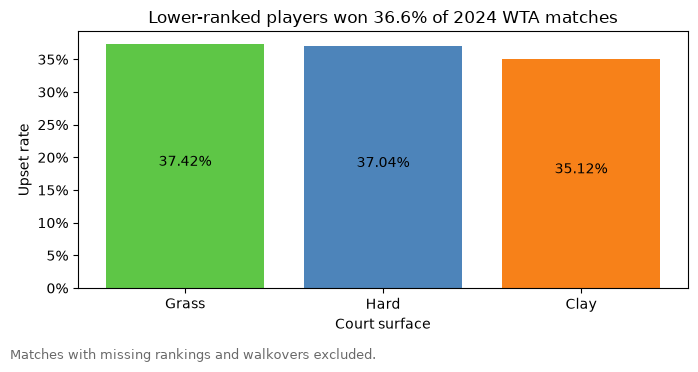

In [48]:
fig, ax = plt.subplots(figsize=(7, 4))

bars = ax.bar(
    surface_stats_2024.index,
    surface_stats_2024["upset_rate"],
    color=["#5ec646", "#4d84ba", "#f78119"][:len(surface_stats_2024)],
)

#for surface in surface_order:
 #   ax.bar(
 #       plot_data.index,
  #      plot_data[surface],
   #     label=surface,
   #     color=colours[surface],
   #     marker="o",
    #    linewidth=1,
  #  )

ax.set_title(f"Lower-ranked players won {upset_percentage_2024:.1f}% of 2024 WTA matches")
ax.set_xlabel("Court surface")
ax.set_ylabel("Upset rate")
ax.yaxis.set_major_formatter(PercentFormatter(1,decimals=0))

for bar, rate in zip(bars, surface_stats_2024["upset_rate"]):
    ax.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height() /2,
        f"{rate:.2%}",
        ha="center",
    )

fig.text(
    0.01,
    0.01,
    #"Upset = lower-ranked player defeated higher-ranked player. \n"
    "Matches with missing rankings and walkovers excluded.",
    fontsize=9,
    color="dimgray",
)


fig.tight_layout(rect=(0, 0.04, 1, 0.92))
fig.savefig("../figures/2024_upset_rate_by_surface.png", dpi=300,bbox_inches="tight",)
plt.show()




We see that the upset rate for 2024 is roughly 35-37% no matter the surface. It is good to check that these percentages are formed from a large enough sample size, so, we check how many matches are played on each surface. We see in the chart below that there were much fewer grass court matches in the WTA season, compared to the other two surfaces, with hard court being the most frequent.

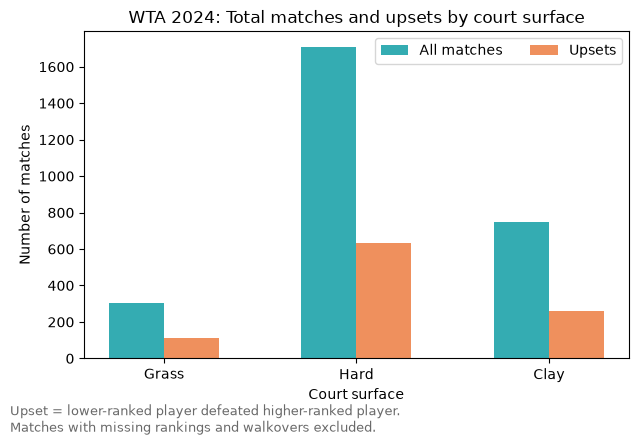

In [49]:
surface_matches_2024 = surface_stats_2024[["matches","upsets"]]

fig, ax = plt.subplots()

ax.grouped_bar(surface_matches_2024,
               colors=["#34ACB2", "#EF905D"])

ax.set_xlabel('Court surface')
ax.set_ylabel('Number of matches')
ax.set_title("WTA 2024: Total matches and upsets by court surface")
ax.legend(labels=["All matches", "Upsets"], loc='upper right', ncols=2)

fig.text(
    0.01,
    0.01,
    "Upset = lower-ranked player defeated higher-ranked player. \n"
    "Matches with missing rankings and walkovers excluded.",
    fontsize=9,
    color="dimgray",
)

fig.tight_layout(rect=(0, 0.04, 1, 0.92))
fig.savefig("../figures/2024_total_matches_vs_upsets_by_surface.png", dpi=300,bbox_inches="tight",)
plt.show()

## Comparing upset rates by court surface over time

As we saw earlier, the set of surfaces played on are Hard, Grass, Clay, and Carpet. Each of hard, grass and clay are surfaces used for Grand Slam tournaments and other major tournaments, yet carpet seems less frequent, especially in recent years. We check how many matches took place on carpet each year.

In [50]:
carpet_matches = matches.loc[matches["surface"] == "Carpet"]
carpet_matches.value_counts("year").sort_index()

year
2000    251
2001    194
2002    163
2003    184
2004     93
2005     84
2006     83
2007     62
2008     82
2009     34
2010     37
2011     29
2012     29
2013     27
2014     27
Name: count, dtype: int64

We see that the number of matches on carpet increased most years between 2000 and 2014, and stopped altogether from 2015 onwards. Since we are interested in comparing the surfaces all the way until 2025, we choose to disregard all matches played on carpet for this comparison, and only focus on the three main surfaces. Let us now consider some basic statistics on the data given for these categories.

In [51]:
surface_order = ["Hard", "Clay", "Grass"]

annual_surface_rates = (
    matches
    .dropna(subset=["year", "surface", "is_upset"])
    .loc[lambda data: data["surface"].isin(surface_order)]
    .groupby(["year", "surface"], as_index=False)
    .agg(
        upset_rate=("is_upset", "mean"),
        upset_count=("is_upset", "sum"),
    )
)

annual_surface_rates.head()

,year,surface,upset_rate,upset_count
0,2000,Clay,0.347011,296
1,2000,Grass,0.34375,110
2,2000,Hard,0.312709,374
3,2001,Clay,0.375697,337
4,2001,Grass,0.328571,92


In [52]:
plot_data = (
    annual_surface_rates
    .pivot(
        index="year",
        columns="surface",
        values="upset_rate",
    )
    .reindex(columns=surface_order)
)

plot_data.head()

surface,Hard,Clay,Grass
year,,,
2000,0.312709,0.347011,0.34375
2001,0.306327,0.375697,0.328571
2002,0.329554,0.376596,0.314741
2003,0.296353,0.330664,0.331343
2004,0.322855,0.32782,0.404255


In [53]:
colours = {
    "Hard": "#457B9D",
    "Clay": "#C65D3B",
    "Grass": "#6A994E",
}

Let's make a plot to show this.

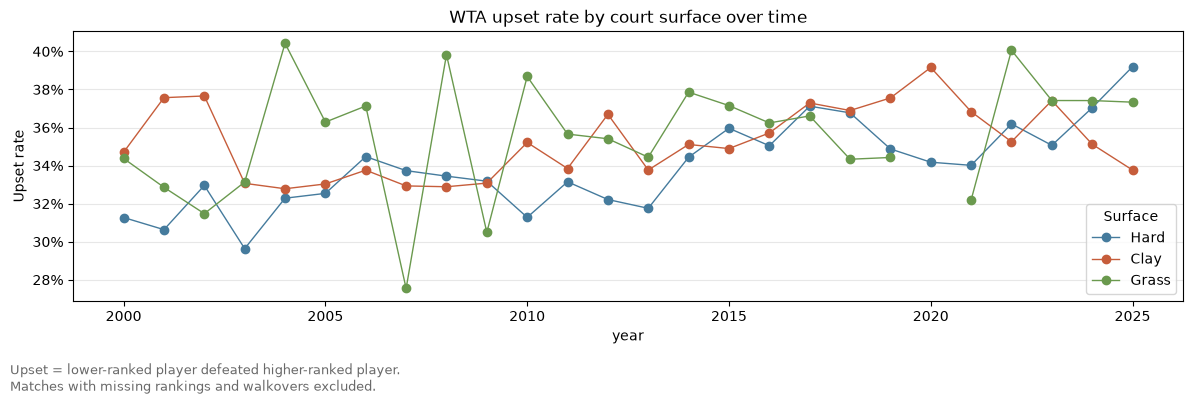

In [54]:
fig, ax = plt.subplots(figsize=(12, 4))

for surface in surface_order:
    ax.plot(
        plot_data.index,
        plot_data[surface],
        label=surface,
        color=colours[surface],
        marker="o",
        linewidth=1,
    )

ax.set_title("WTA upset rate by court surface over time")
ax.set_xlabel("year")
ax.set_ylabel("Upset rate")

ax.yaxis.set_major_formatter(
    PercentFormatter(xmax=1, decimals=0)
)

ax.legend(title="Surface", loc = 'lower right')
ax.grid(axis="y", alpha=0.3)

fig.text(
    0.01,
    0.01,
    "Upset = lower-ranked player defeated higher-ranked player. \n"
    "Matches with missing rankings and walkovers excluded.",
    fontsize=9,
    color="dimgray",
)

fig.tight_layout(rect=(0, 0.09, 1, 1))
fig.savefig("../figures/upset_rate_by_surface.png", dpi=300,bbox_inches="tight",)
plt.show()

It seems that no specific surface consistenly has a higher upset rate than the other two main surfaces, seen by the many overlaps in the figure. The maximum and minimum upset rates were both observed on grass courts. One possible reason for this could be that there are fewer grass court matches per year, and therefore the data is more skewed. Similarly as we did for the specific 2024 data, we display the number of matches and upsets for each year, and for each surface. 

In [55]:
year_surface_counts = (
    matches
    .loc[matches["surface"].isin(surface_order)]
    .groupby(["year", "surface"], as_index=False)
    .agg(
        total_matches=("is_upset", "size"),
        upset_matches=("is_upset", "sum"),
    )
)

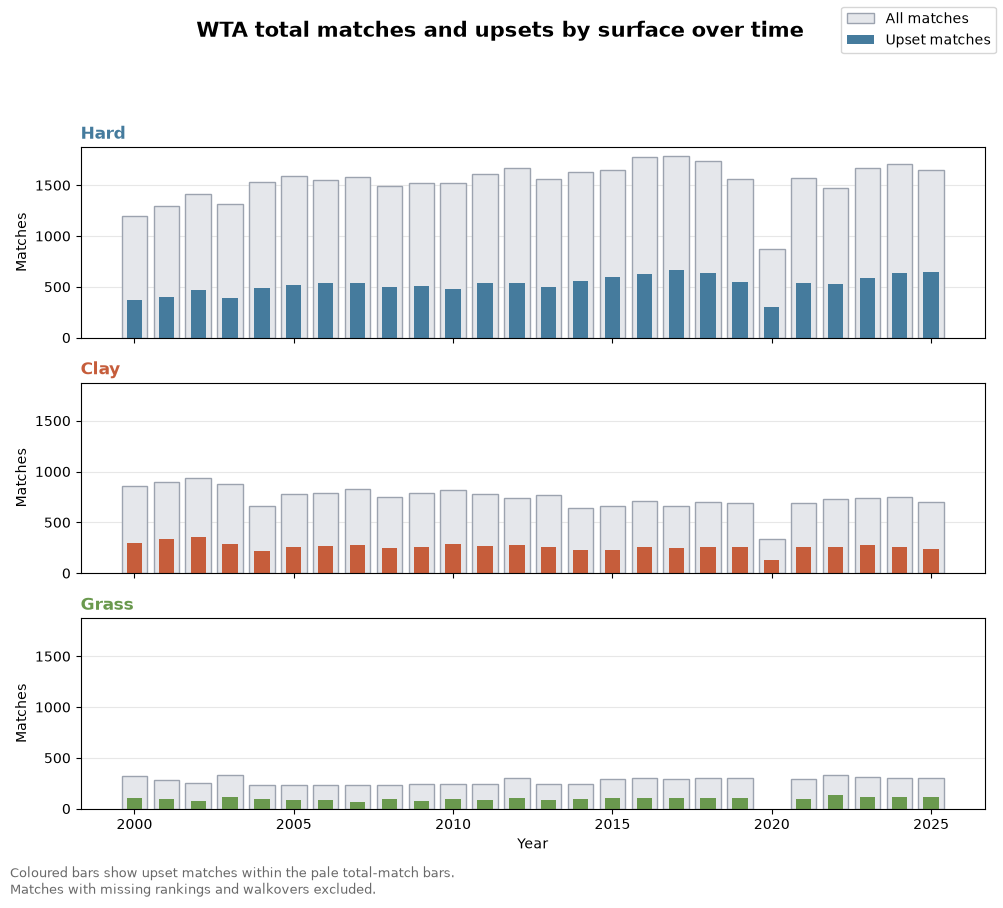

In [56]:
from matplotlib.patches import Patch

fig, axes = plt.subplots(
    nrows=3,
    ncols=1,
    figsize=(10, 9),
    sharex=True,
    sharey=True,
)

for ax, surface in zip(axes, surface_order):
    surface_data = year_surface_counts.loc[
        year_surface_counts["surface"] == surface
    ]

    ax.bar(
        surface_data["year"],
        surface_data["total_matches"],
        width=0.8,
        color="#E5E7EB",
        edgecolor="#9CA3AF",
    )

    ax.bar(
        surface_data["year"],
        surface_data["upset_matches"],
        width=0.48,
        color=colours[surface],
    )

    ax.set_title(surface, loc="left", color=colours[surface], weight="bold")
    ax.set_ylabel("Matches")
    ax.grid(axis="y", alpha=0.3)
    ax.set_axisbelow(True)

axes[-1].set_xlabel("Year")

years = sorted(year_surface_counts["year"].unique())
axes[-1].set_xticks(years[::5])

fig.suptitle(
    "WTA total matches and upsets by surface over time",
    fontsize=15,
    weight="bold",
)

fig.legend(
    handles=[
        Patch(
            facecolor="#E5E7EB",
            edgecolor="#9CA3AF",
            label="All matches",
        ),
        Patch(
            facecolor="#457B9D",
            label="Upset matches",
        ),
    ],
    loc="upper right",
    ncols=1,
    frameon=True,
)

fig.text(
    0.01,
    0.01,
    "Coloured bars show upset matches within the pale total-match bars.\n"
    #"Upset = lower-ranked player defeated higher-ranked player. \n"
    "Matches with missing rankings and walkovers excluded.",
    fontsize=9,
    color="dimgray",
)

fig.tight_layout(rect=(0, 0.04, 1, 0.92))
fig.savefig("../figures/total_upsets_by_surface.png", dpi=300,bbox_inches="tight",)
plt.show()

We notice that there were no matches played on grass in 2020. This was due to the Covid-19 pandemic and the cancellation of WTA tournaments which result in the grass swing being missed.

## Comparing upsets by ranking gap

Does the ranking gap between competitors affect the likelihood of an upset? We consider this question here, by partitioning the ranking gaps into intervals of length 10, and determining the upset rate amongst all matches with a ranking gap in one of these intervals.

In [57]:
gap_edges = [0, 10, 20, 30, 40, 50, 60, 70, 80, 90, 100, np.inf]
gap_labels = ["0–9", "10–19", "20-29", "30–39","40–49","50–59", "60-69", "70-79", "80-89", "90-99", "100+"]

In [58]:
matches["rank_gap_group"] = pd.cut(
    matches["rank_gap"],
    bins=gap_edges,
    labels=gap_labels,
    right=False,
)

In [59]:
gap_stats = (
    matches.groupby("rank_gap_group", observed=True)
    .agg(
        upset_rate=("is_upset", "mean"),
        matches=("is_upset", "size"),
        upsets=("is_upset", "sum"),
    )
    #.sort_values("upset_rate", ascending=False)
)

gap_stats

,upset_rate,matches,upsets
rank_gap_group,,,
0–9,0.45788,8725,3995
10–19,0.411624,9171,3775
20-29,0.388348,7913,3073
30–39,0.361257,6685,2415
40–49,0.333927,5612,1874
50–59,0.322212,4556,1468
60-69,0.299373,3828,1146
70-79,0.301004,3186,959
80-89,0.289442,2529,732


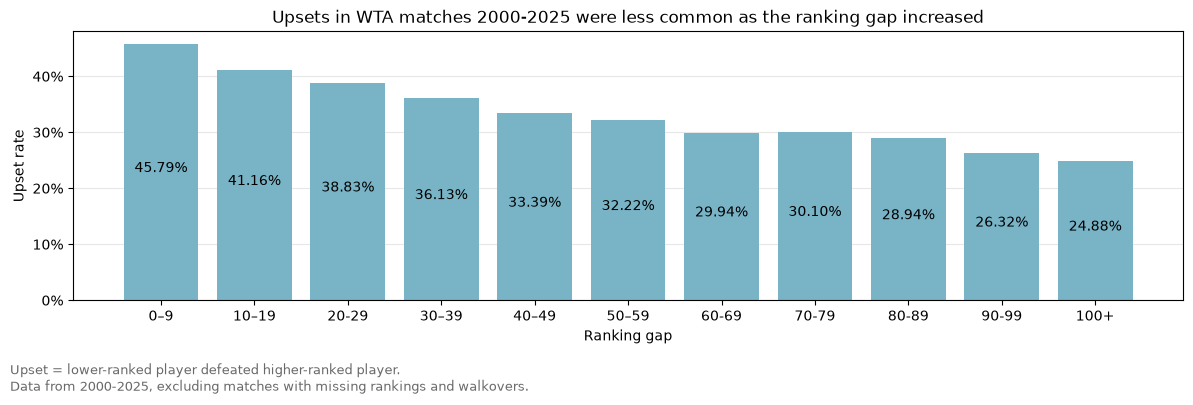

In [60]:
fig, ax = plt.subplots(figsize=(12, 4))

bars = ax.bar(
    gap_stats.index,
    gap_stats["upset_rate"],
    color=["#78b3c6"][:len(gap_stats)],
)

ax.set_title("Upsets in WTA matches 2000-2025 were less common as the ranking gap increased")
ax.set_xlabel("Ranking gap")
ax.set_ylabel("Upset rate")
ax.yaxis.set_major_formatter(PercentFormatter(1,decimals=0))

for bar, rate in zip(bars, gap_stats["upset_rate"]):
    ax.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height() /2,
        f"{rate:.2%}",
        ha="center",
    )

ax.grid(axis="y", alpha=0.3)
ax.set_axisbelow(True)

fig.text(
    0.01,
    0.01,
    "Upset = lower-ranked player defeated higher-ranked player. \n"
    "Data from 2000-2025, excluding matches with missing rankings and walkovers.",
    fontsize=9,
    color="dimgray",
)

fig.tight_layout(rect=(0, 0.09, 1, 1))

fig.savefig("../figures/upset_rate_by_rank_gap.png", dpi=300,bbox_inches="tight",)
plt.show()


There is a fairly consistent trend in the upset rate decreasing as the ranking gap increases.

In [61]:
upset_matches = matches[matches['is_upset'] == True]

## Comparing upset rates by tournament round

Does the upset rate depend on which round of the tournament we are in? 

We are interested in tournaments that were played in the standard progression format, i.e. there was a final, two semifinals, four quarterfinals, and so on. So, we ignore all matches that have were played in a round robin (RR) format. We also ignore bronze medal (BR) matches, because only five such matches took place between 2000 and 2025, and therefore there is not enough data to calculate a meaningful upset rate.

In [62]:
main_rounds = ["R128", "R64", "R32", "R16", "QF", "SF", "F"]
main_round_matches = matches[matches['round'].isin(main_rounds)]

round_stats = (
    main_round_matches.groupby(["round"])
    .agg(
        upset_rate=("is_upset", "mean"),
        matches=("is_upset", "size"),
        upsets=("is_upset", "sum"),
    )
    .sort_values(["upset_rate"], ascending=False)
    ).reindex(index=main_rounds)

round_stats

,upset_rate,matches,upsets
round,,,
R128,0.335229,8439,2829
R64,0.339332,10447,3545
R32,0.353294,21843,7717
R16,0.341388,11629,3970
QF,0.357155,5835,2084
SF,0.378397,2981,1128
F,0.383444,1510,579


Interestingly, the upset rate mostly increased as the tournament progressed, that is, there were fewer upsets on average in earlier rounds, and more upsets at later stages. We can display this as a bar chart.

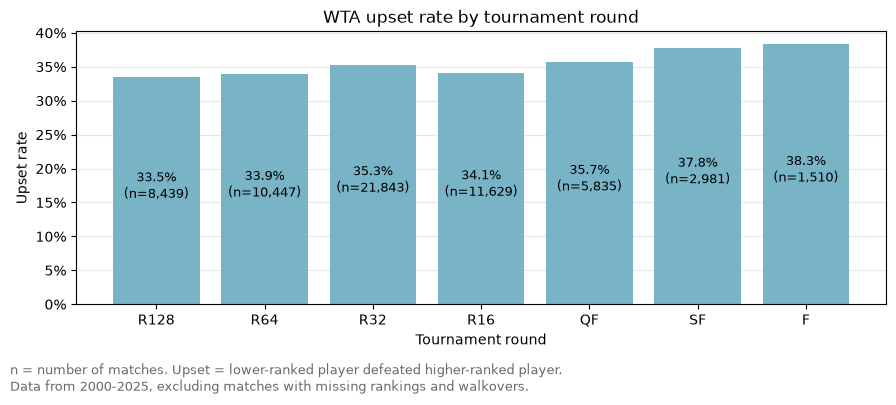

In [63]:
fig, ax = plt.subplots(figsize=(9, 4))


bars = ax.bar(
    round_stats.index,
    round_stats["upset_rate"],
    color="#78b3c6",
)

ax.set_title("WTA upset rate by tournament round")
ax.set_xlabel("Tournament round")
ax.set_ylabel("Upset rate")

ax.yaxis.set_major_formatter(
    PercentFormatter(xmax=1, decimals=0)
)

labels = [
    f"{rate:.1%}\n(n={match_count:,})"
    for rate, match_count in zip(
        round_stats["upset_rate"],
        round_stats["matches"],
    )
]

ax.bar_label(
    bars,
    labels=labels,
    label_type="center",
    fontsize=9,
    padding=3,
)

ax.grid(axis="y", alpha=0.3)
ax.set_axisbelow(True)

fig.text(
    0.01,
    0.01,
    "n = number of matches. Upset = lower-ranked player defeated higher-ranked player.\n"
    "Data from 2000-2025, excluding matches with missing rankings and walkovers.",
    fontsize=9,
    color="dimgray",
)

fig.tight_layout(rect=(0, 0.08, 1, 1))

fig.savefig("../figures/upset_rate_by_round.png", dpi=300,bbox_inches="tight",)
plt.show()

### Saving the data for our next step: feature engineering

In [64]:
matches.to_csv("../data/processed/matches_clean.csv", index=False)